In [16]:
pip install iTransformer optuna pandas numpy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [17]:
# Import shared modules
import sys
sys.path.append('.')

from data_loader import load_btc_data, load_sentiment_data, load_technical_data, process_sentiment_hourly, merge_dataframes, create_hourly_data, create_validation_periods, create_sequences
from model_utils import load_model, make_predictions, prepare_tensor
from backtest_functions import backtest_profit_threshold_with_trades, backtest_profit_threshold, backtest_ts_momentum
from utils import optimize_kelly_parameters, plot_trades, save_trades_to_csv, create_trades_dataframe

# Force reload modules
import importlib
import data_loader
importlib.reload(data_loader)
import utils
importlib.reload(utils)

# Import CV functions after reload
from utils import cv_optimize_threshold_parameters, cv_optimize_risk_parameters, cv_optimize_momentum_parameters
from data_loader import create_validation_periods
from utils import cv_optimize_threshold_parameters

# Debug: check utils module location
print(f"Utils module location: {utils.__file__}")
print(f"CV function exists: {hasattr(utils, 'cv_optimize_threshold_parameters')}")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

Utils module location: /home/kosmo/Documents/Magis-files/vibe-test/utils.py
CV function exists: True


In [18]:
path = "./data/"

In [19]:
# Load all data for full dataset backtesting
print("Loading BTC data...")
df = load_btc_data(path)

print("Loading sentiment data...")
df_sentiments = load_sentiment_data(path)

print("Loading technical data...")
technical_data = load_technical_data(path)

print("Processing sentiment data...")
df_hourly_sentiments = process_sentiment_hourly(df_sentiments)

print("Merging all data...")
merged_df = merge_dataframes(df, df_hourly_sentiments, technical_data)

print("Creating hourly data...")
features = ['price_change_1h', 'close', 'usd_volume_buy', 'usd_volume_sell', 'close_gold', 'close_sp500', 'close_vxx', 'tx_count', 'blocks_mined', 'est_hashrate', 'predicted_sentiment_24h_avg', 'predicted_sentiment_4h_decay']
df_hourly = create_hourly_data(merged_df, features)

print(f"Data shape: {df_hourly.shape}")
df_hourly.head()

Loading BTC data...
Loading sentiment data...
Loading technical data...
Loading sentiment data...
Loading technical data...
Processing sentiment data...
Processing sentiment data...
Merging all data...
Merging all data...
Creating hourly data...
Creating hourly data...
Data shape: (51532, 12)
Data shape: (51532, 12)


,price_change_1h,close,usd_volume_buy,usd_volume_sell,close_gold,close_sp500,close_vxx,tx_count,blocks_mined,est_hashrate,predicted_sentiment_24h_avg,predicted_sentiment_4h_decay
datetime,,,,,,,,,,,,
2019-09-30 14:00:00+00:00,86.81,8201.57,1.479622e+07,2.620998e+07,14.165,272.44,23.790,21584.0,8.0,2.062409e+07,0.0,0.0
2019-09-30 17:00:00+00:00,-29.23,8230.78,5.038690e+06,1.340925e+07,14.045,273.08,23.565,14150.0,5.0,8.067181e+06,0.0,0.0
2019-09-30 18:00:00+00:00,28.18,8258.96,6.928682e+06,1.355439e+07,14.095,272.96,23.700,21515.0,7.0,9.818671e+06,0.0,0.0
2019-09-30 19:00:00+00:00,10.57,8269.53,3.306980e+06,5.958969e+06,14.095,272.71,23.730,24767.0,8.0,1.119939e+07,0.0,0.0
2019-09-30 20:00:00+00:00,-54.86,8214.67,8.088017e+06,1.757720e+07,14.095,272.71,23.730,20479.0,7.0,1.019490e+07,0.0,0.0


In [20]:
# Create validation periods
train_df, val_df_period1, val_df_period2 = create_validation_periods(df_hourly)

print(f"Training data: {len(train_df)} samples")
print(f"Period 1 validation: {len(val_df_period1)} samples")
print(f"Period 2 validation: {len(val_df_period2)} samples")

# Create sequences for period 1
seq_length = 24*7  # 7 days
X_val_p1, y_val_p1 = create_sequences(val_df_period1, 'price_change_1h', seq_length)
X_val_p2, y_val_p2 = create_sequences(val_df_period2, 'price_change_1h', seq_length)

print(f"Period 1 - X shape: {X_val_p1.shape}, y shape: {y_val_p1.shape}")
print(f"Period 2 - X shape: {X_val_p2.shape}, y shape: {y_val_p2.shape}")

# Use period 1 for initial testing
X_val, y_val = X_val_p1, y_val_p1

Training data: 40103 samples
Period 1 validation: 4305 samples
Period 2 validation: 4283 samples
Period 1 - X shape: (4137, 168, 11), y shape: (4137,)
Period 2 - X shape: (4115, 168, 11), y shape: (4115,)


In [21]:
# Recreate sequences with correct shape
seq_length = 24*7  # 7 days
X_val_correct, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
print(f"Corrected X_val shape: {X_val_correct.shape}")

# Load model
model_path = 'dim-128_depth-2_heads-32_lr-0(2)-1token.005194333717324816.pth'
print(f"Loading model from {model_path}")
model, device = load_model(model_path, num_variates=11, lookback_len=24*7, dim=128, depth=2, heads=32)
print(f"Model loaded on device: {device}")

# Prepare data
X_val_tensor = prepare_tensor(X_val_correct, device)
print(f"X_val_tensor shape: {X_val_tensor.shape}, device: {X_val_tensor.device}")

# Make predictions
print("Making predictions...")
val_pred_1h_change = make_predictions(model, X_val_tensor, device, df_hourly.columns.get_loc('price_change_1h'))

# Get close prices for backtesting
close_price = val_df_period1['close'][seq_length:].values

print(f"Predictions shape: {val_pred_1h_change.shape}")
print(f"Close price shape: {close_price.shape}")

Corrected X_val shape: (4137, 168, 11)
Loading model from dim-128_depth-2_heads-32_lr-0(2)-1token.005194333717324816.pth
Model loaded on device: cuda
X_val_tensor shape: torch.Size([4137, 168, 11]), device: cuda:0
Making predictions...
Predictions shape: (4137,)
Close price shape: (4137,)
Predictions shape: (4137,)
Close price shape: (4137,)


Performing CV optimization on training data...
CV optimizing threshold parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...


[I 2025-12-09 20:48:43,800] A new study created in memory with name: no-name-c8da7796-8d08-4746-8dc5-8daf396c1126
[I 2025-12-09 20:48:43,828] Trial 1 finished with value: 0.6276541593503481 and parameters: {'threshold': 0.9486828485906833, 'hold_hours': 124}. Best is trial 1 with value: 0.6276541593503481.
[I 2025-12-09 20:48:43,828] Trial 1 finished with value: 0.6276541593503481 and parameters: {'threshold': 0.9486828485906833, 'hold_hours': 124}. Best is trial 1 with value: 0.6276541593503481.
[I 2025-12-09 20:48:43,828] Trial 0 finished with value: 0.5865726619881385 and parameters: {'threshold': 0.6170102953443022, 'hold_hours': 97}. Best is trial 1 with value: 0.6276541593503481.
[I 2025-12-09 20:48:43,839] Trial 2 finished with value: 0.38893046619833793 and parameters: {'threshold': 1.517149227728118, 'hold_hours': 22}. Best is trial 1 with value: 0.6276541593503481.
[I 2025-12-09 20:48:43,828] Trial 0 finished with value: 0.5865726619881385 and parameters: {'threshold': 0.6170

Fold 1 - Best threshold: 0.30%, Hold hours: 111, Sharpe: 0.88
Processing CV fold 2/10...


[I 2025-12-09 20:48:47,291] A new study created in memory with name: no-name-c8e5dec3-f960-4a9a-b7c7-41602160fae2
[I 2025-12-09 20:48:47,303] Trial 0 finished with value: 1.747451709885949 and parameters: {'threshold': 1.2938524646442628, 'hold_hours': 103}. Best is trial 0 with value: 1.747451709885949.
[I 2025-12-09 20:48:47,303] Trial 0 finished with value: 1.747451709885949 and parameters: {'threshold': 1.2938524646442628, 'hold_hours': 103}. Best is trial 0 with value: 1.747451709885949.
[I 2025-12-09 20:48:47,331] Trial 2 finished with value: 1.4784160176651606 and parameters: {'threshold': 0.9145307052164562, 'hold_hours': 57}. Best is trial 0 with value: 1.747451709885949.
[I 2025-12-09 20:48:47,332] Trial 1 finished with value: 1.5014404777576014 and parameters: {'threshold': 0.7560202787695787, 'hold_hours': 91}. Best is trial 0 with value: 1.747451709885949.
[I 2025-12-09 20:48:47,331] Trial 2 finished with value: 1.4784160176651606 and parameters: {'threshold': 0.9145307052

Fold 2 - Best threshold: 0.20%, Hold hours: 78, Sharpe: 2.45
Processing CV fold 3/10...


[I 2025-12-09 20:48:50,757] A new study created in memory with name: no-name-2775741b-d49d-41e8-a6b5-cb4694640947
[I 2025-12-09 20:48:50,776] Trial 0 finished with value: 4.287423075433862 and parameters: {'threshold': 0.5755821260496108, 'hold_hours': 112}. Best is trial 0 with value: 4.287423075433862.
[I 2025-12-09 20:48:50,776] Trial 0 finished with value: 4.287423075433862 and parameters: {'threshold': 0.5755821260496108, 'hold_hours': 112}. Best is trial 0 with value: 4.287423075433862.
[I 2025-12-09 20:48:50,815] Trial 3 finished with value: 4.215475008130184 and parameters: {'threshold': 0.6079853566778369, 'hold_hours': 101}. Best is trial 0 with value: 4.287423075433862.
[I 2025-12-09 20:48:50,815] Trial 3 finished with value: 4.215475008130184 and parameters: {'threshold': 0.6079853566778369, 'hold_hours': 101}. Best is trial 0 with value: 4.287423075433862.
[I 2025-12-09 20:48:50,815] Trial 4 finished with value: 3.8312203324487037 and parameters: {'threshold': 1.2217067982

... (11 outputs left out)

[I 2025-12-09 20:49:11,575] A new study created in memory with name: no-name-fe54e7ee-98c3-4001-bfcf-8eba2fd3da34
[I 2025-12-09 20:49:11,587] Trial 0 finished with value: 1.8699047234757864 and parameters: {'threshold': 0.09639995328398933, 'hold_hours': 36}. Best is trial 0 with value: 1.8699047234757864.
[I 2025-12-09 20:49:11,587] Trial 0 finished with value: 1.8699047234757864 and parameters: {'threshold': 0.09639995328398933, 'hold_hours': 36}. Best is trial 0 with value: 1.8699047234757864.
[I 2025-12-09 20:49:11,603] Trial 1 finished with value: 2.204824262118708 and parameters: {'threshold': 0.3253156756424759, 'hold_hours': 157}. Best is trial 1 with value: 2.204824262118708.
[I 2025-12-09 20:49:11,603] Trial 1 finished with value: 2.204824262118708 and parameters: {'threshold': 0.3253156756424759, 'hold_hours': 157}. Best is trial 1 with value: 2.204824262118708.
[I 2025-12-09 20:49:11,610] Trial 2 finished with value: 2.1264619584357254 and parameters: {'threshold': 1.655595

Fold 9 - Best threshold: 1.55%, Hold hours: 4, Sharpe: 2.92
Processing CV fold 10/10...


[I 2025-12-09 20:49:14,927] A new study created in memory with name: no-name-5e2a7f64-4926-4624-aae5-af4c41bee91d
[I 2025-12-09 20:49:14,938] Trial 0 finished with value: 1.489330058443035 and parameters: {'threshold': 0.26960682456477114, 'hold_hours': 50}. Best is trial 0 with value: 1.489330058443035.
[I 2025-12-09 20:49:14,949] Trial 1 finished with value: 1.7816108355106834 and parameters: {'threshold': 0.6938611015149984, 'hold_hours': 84}. Best is trial 1 with value: 1.7816108355106834.
[I 2025-12-09 20:49:14,938] Trial 0 finished with value: 1.489330058443035 and parameters: {'threshold': 0.26960682456477114, 'hold_hours': 50}. Best is trial 0 with value: 1.489330058443035.
[I 2025-12-09 20:49:14,949] Trial 1 finished with value: 1.7816108355106834 and parameters: {'threshold': 0.6938611015149984, 'hold_hours': 84}. Best is trial 1 with value: 1.7816108355106834.
[I 2025-12-09 20:49:14,959] Trial 2 finished with value: 1.870790077733493 and parameters: {'threshold': 0.666168677

Fold 10 - Best threshold: 1.00%, Hold hours: 144, Sharpe: 2.00
CV Best threshold: 1.12%, Hold hours: 69, Average Sharpe ratio: 1.67

Optimized parameters:
Threshold: 1.12%
Hold Hours: 69

BACKTESTING ON TEST DATA

--- Test Period 1 ---
Backtest trades saved to backtest_results/full_dataset/threshold_backtest_trades-1.csv (161 trades)
Backtest trades saved to backtest_results/full_dataset/threshold_backtest_trades-1.csv (161 trades)


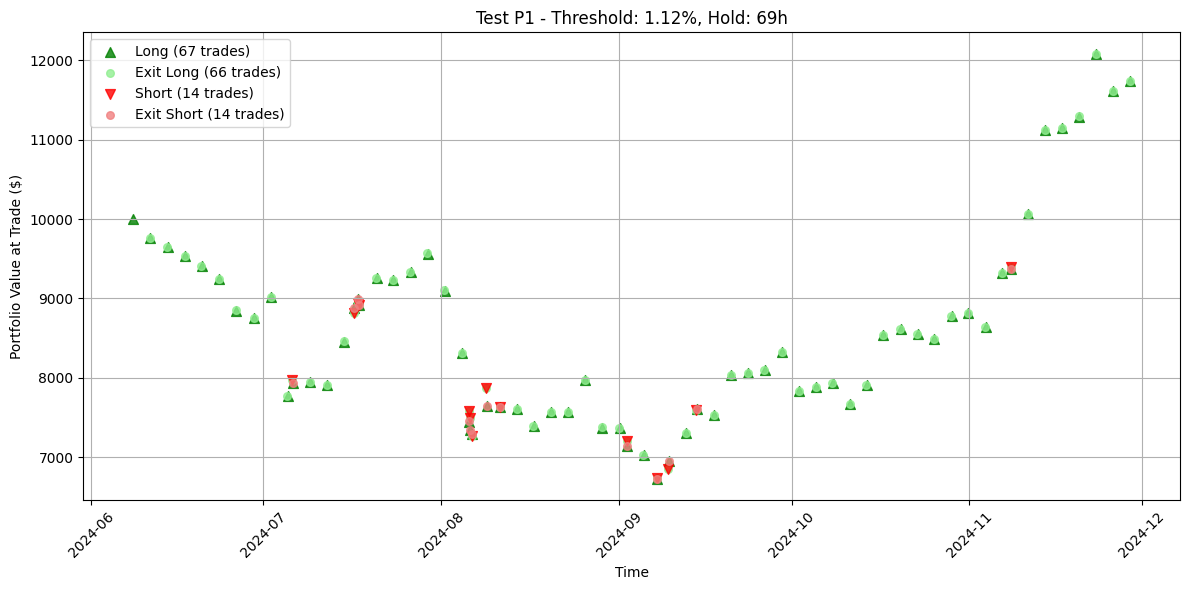


--- Test Period 2 ---
Backtest trades saved to backtest_results/full_dataset/threshold_backtest_trades-2.csv (131 trades)
Backtest trades saved to backtest_results/full_dataset/threshold_backtest_trades-2.csv (131 trades)


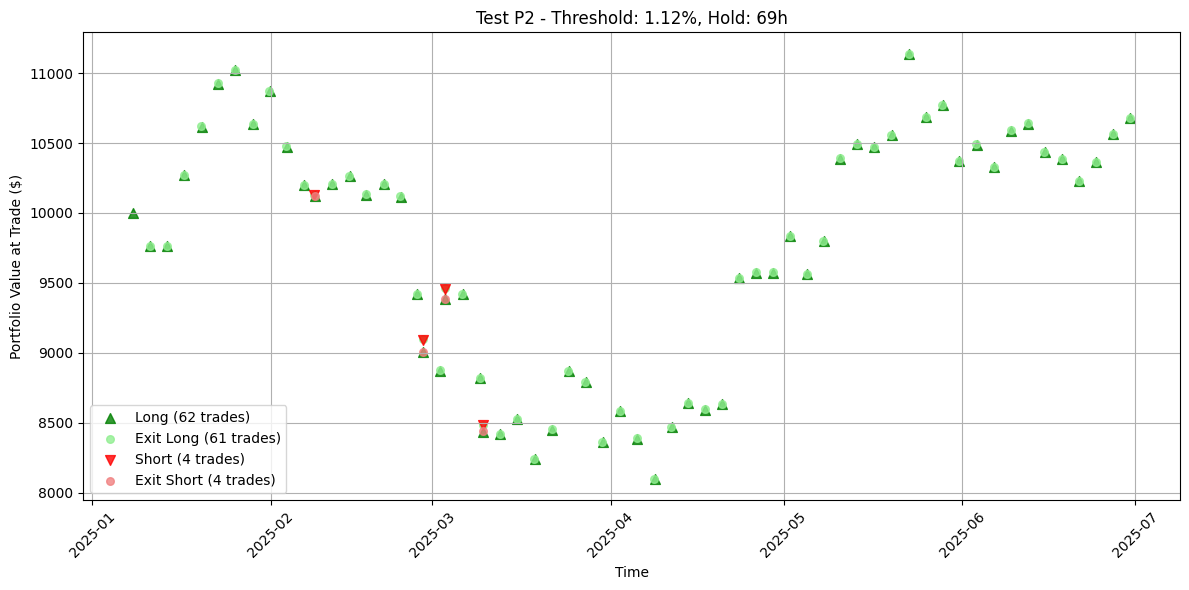

In [22]:
# CV Optimization and Backtesting on Test Data
initial_capital = 10000
fixed_transaction_cost_pct = 0.0275
seq_length = 24*7  # 7 days

print("Performing CV optimization on training data...")

# CV optimize threshold parameters
print("CV optimizing threshold parameters...")
# Load CPU model for CV
cv_model, cv_device = load_model(model_path, num_variates=11, lookback_len=24*7, dim=128, depth=2, heads=32, device='cpu')
best_threshold, best_hold_hours = cv_optimize_threshold_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=False
)



print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

# Now backtest on test periods with optimized parameters
print("\n" + "="*50)
print("BACKTESTING ON TEST DATA")
print("="*50)

# Test Period 1 Backtests
print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Threshold backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Threshold Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/threshold_backtest_trades-1.csv')
plot_trades(trades_df, f'Test P1 - Threshold: {best_threshold:.2f}%, Hold: {best_hold_hours}h')



# Test Period 2 Backtests
print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Threshold backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Threshold Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/threshold_backtest_trades-2.csv')
plot_trades(trades_df, f'Test P2 - Threshold: {best_threshold:.2f}%, Hold: {best_hold_hours}h')


CV optimizing risk parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for risk optimization...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for risk optimization...


[I 2025-12-09 20:49:19,367] A new study created in memory with name: no-name-4f4f80ed-e8fe-4a7c-8b8c-e9fbb37a83f7
[I 2025-12-09 20:49:19,389] Trial 0 finished with value: 0.3917344699446308 and parameters: {'threshold': 1.52146084361034, 'target_risk': 1.5021900485213227, 'hold_hours': 118}. Best is trial 0 with value: 0.3917344699446308.
[I 2025-12-09 20:49:19,389] Trial 0 finished with value: 0.3917344699446308 and parameters: {'threshold': 1.52146084361034, 'target_risk': 1.5021900485213227, 'hold_hours': 118}. Best is trial 0 with value: 0.3917344699446308.
[I 2025-12-09 20:49:19,439] Trial 5 finished with value: -0.07282001506639661 and parameters: {'threshold': 1.9046649568387166, 'target_risk': 0.8167231942170375, 'hold_hours': 158}. Best is trial 0 with value: 0.3917344699446308.
[I 2025-12-09 20:49:19,439] Trial 5 finished with value: -0.07282001506639661 and parameters: {'threshold': 1.9046649568387166, 'target_risk': 0.8167231942170375, 'hold_hours': 158}. Best is trial 0 wi

Fold 1 - Best threshold: 0.44%, Risk: 1.94%, Hold hours: 4, Sharpe: 1.40
Processing CV fold 2/10 for risk optimization...


[I 2025-12-09 20:49:32,554] A new study created in memory with name: no-name-0d6d81a2-06af-4f72-b54d-d5c6bf86e689
[I 2025-12-09 20:49:32,574] Trial 1 finished with value: 1.716032902548216 and parameters: {'threshold': 0.7468703269382737, 'target_risk': 1.7051260348197226, 'hold_hours': 160}. Best is trial 1 with value: 1.716032902548216.
[I 2025-12-09 20:49:32,583] Trial 0 finished with value: 1.8081551488619707 and parameters: {'threshold': 1.2048679685538595, 'target_risk': 2.1508336497653118, 'hold_hours': 133}. Best is trial 0 with value: 1.8081551488619707.
[I 2025-12-09 20:49:32,574] Trial 1 finished with value: 1.716032902548216 and parameters: {'threshold': 0.7468703269382737, 'target_risk': 1.7051260348197226, 'hold_hours': 160}. Best is trial 1 with value: 1.716032902548216.
[I 2025-12-09 20:49:32,583] Trial 0 finished with value: 1.8081551488619707 and parameters: {'threshold': 1.2048679685538595, 'target_risk': 2.1508336497653118, 'hold_hours': 133}. Best is trial 0 with v

Fold 2 - Best threshold: 0.28%, Risk: 0.04%, Hold hours: 54, Sharpe: 2.83
Processing CV fold 3/10 for risk optimization...


[I 2025-12-09 20:49:44,746] A new study created in memory with name: no-name-ae4ec61d-eb3d-447f-86e0-1ca987e634d3
[I 2025-12-09 20:49:44,790] Trial 0 finished with value: 1.978300239270667 and parameters: {'threshold': 1.303811604775122, 'target_risk': 1.022578169751862, 'hold_hours': 2}. Best is trial 0 with value: 1.978300239270667.
[I 2025-12-09 20:49:44,790] Trial 0 finished with value: 1.978300239270667 and parameters: {'threshold': 1.303811604775122, 'target_risk': 1.022578169751862, 'hold_hours': 2}. Best is trial 0 with value: 1.978300239270667.
[I 2025-12-09 20:49:44,796] Trial 2 finished with value: 3.7780595983707954 and parameters: {'threshold': 0.051297286657614995, 'target_risk': 1.4302383623834896, 'hold_hours': 17}. Best is trial 2 with value: 3.7780595983707954.
[I 2025-12-09 20:49:44,796] Trial 2 finished with value: 3.7780595983707954 and parameters: {'threshold': 0.051297286657614995, 'target_risk': 1.4302383623834896, 'hold_hours': 17}. Best is trial 2 with value: 

... (11 outputs left out)

[I 2025-12-09 20:50:59,439] A new study created in memory with name: no-name-11dd3f6e-1076-43f7-9be4-b2b7f37458e2
[I 2025-12-09 20:50:59,470] Trial 1 finished with value: 1.9776102196776382 and parameters: {'threshold': 1.2619764288049222, 'target_risk': 1.1962342347145938, 'hold_hours': 71}. Best is trial 1 with value: 1.9776102196776382.
[I 2025-12-09 20:50:59,470] Trial 1 finished with value: 1.9776102196776382 and parameters: {'threshold': 1.2619764288049222, 'target_risk': 1.1962342347145938, 'hold_hours': 71}. Best is trial 1 with value: 1.9776102196776382.
[I 2025-12-09 20:50:59,470] Trial 2 finished with value: 1.716815610336191 and parameters: {'threshold': 1.1354331843555132, 'target_risk': 0.1521783738168236, 'hold_hours': 71}. Best is trial 1 with value: 1.9776102196776382.
[I 2025-12-09 20:50:59,478] Trial 0 finished with value: 1.9659425404582649 and parameters: {'threshold': 0.3202370034578386, 'target_risk': 0.01918408532015195, 'hold_hours': 100}. Best is trial 1 with 

Fold 9 - Best threshold: 0.52%, Risk: 0.49%, Hold hours: 125, Sharpe: 2.88
Processing CV fold 10/10 for risk optimization...


[I 2025-12-09 20:51:11,566] A new study created in memory with name: no-name-afb57d4f-448e-4614-9d5f-91b72fea764a
[I 2025-12-09 20:51:11,591] Trial 1 finished with value: 1.6681962278103235 and parameters: {'threshold': 1.5431208070014988, 'target_risk': 2.458135029881297, 'hold_hours': 76}. Best is trial 1 with value: 1.6681962278103235.
[I 2025-12-09 20:51:11,591] Trial 1 finished with value: 1.6681962278103235 and parameters: {'threshold': 1.5431208070014988, 'target_risk': 2.458135029881297, 'hold_hours': 76}. Best is trial 1 with value: 1.6681962278103235.
[I 2025-12-09 20:51:11,598] Trial 0 finished with value: 0.7072154181250226 and parameters: {'threshold': 1.7573917476070855, 'target_risk': 1.013499511085017, 'hold_hours': 19}. Best is trial 1 with value: 1.6681962278103235.
[I 2025-12-09 20:51:11,598] Trial 0 finished with value: 0.7072154181250226 and parameters: {'threshold': 1.7573917476070855, 'target_risk': 1.013499511085017, 'hold_hours': 19}. Best is trial 1 with value

Fold 10 - Best threshold: 1.39%, Risk: 0.25%, Hold hours: 33, Sharpe: 2.96
CV Optimal threshold: 0.92%, Risk: 0.81%, Hold hours: 49, Average Sharpe: 2.06

Optimized parameters:
Threshold: 0.92%
Target Risk: 0.81%
Hold Hours: 49

--- Test Period 1 ---
Backtest trades saved to backtest_results/full_dataset/risk_based_backtest_trades-1.csv (209 trades)
Backtest trades saved to backtest_results/full_dataset/risk_based_backtest_trades-1.csv (209 trades)


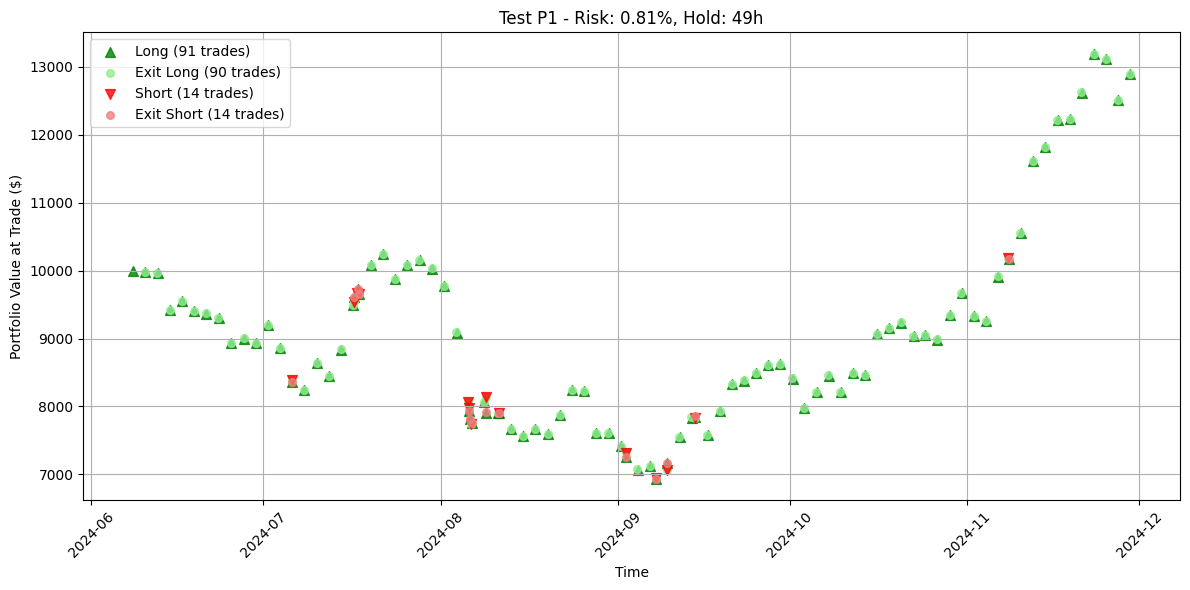


--- Test Period 2 ---
Backtest trades saved to backtest_results/full_dataset/risk_based_backtest_trades-2.csv (179 trades)
Backtest trades saved to backtest_results/full_dataset/risk_based_backtest_trades-2.csv (179 trades)


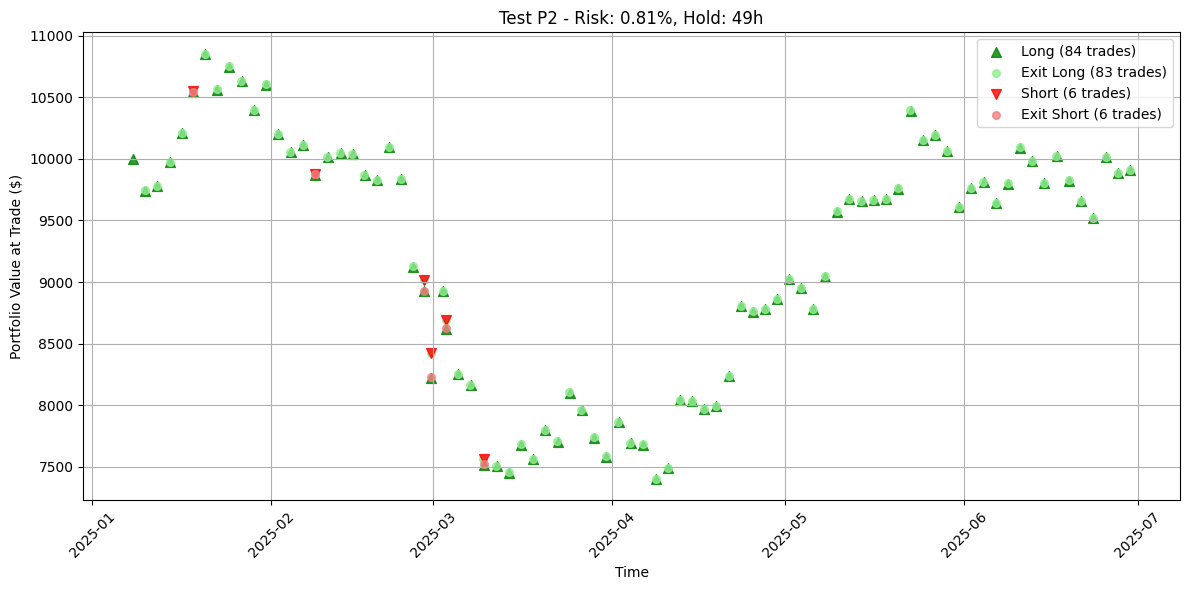

In [23]:
# CV optimize risk parameters
print("CV optimizing risk parameters...")
best_threshold, best_target_risk, best_hold_hours = cv_optimize_risk_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=False
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Target Risk: {best_target_risk:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Risk-based backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Risk-Based Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/risk_based_backtest_trades-1.csv')
plot_trades(trades_df, f'Test P1 - Risk: {best_target_risk:.2f}%, Hold: {best_hold_hours}h')


print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Risk-based backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Risk-Based Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/risk_based_backtest_trades-2.csv')
plot_trades(trades_df, f'Test P2 - Risk: {best_target_risk:.2f}%, Hold: {best_hold_hours}h')

In [24]:
# CV optimize momentum parameters
print("CV optimizing momentum parameters...")
best_lookback, best_hold_hours, best_signal_thresh, best_target_risk= cv_optimize_momentum_parameters(
    train_df, cv_model, seq_length, 'price_change_1h', fixed_transaction_cost_pct, include_target=False
)

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Momentum backtest on period 1
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p1,
    predicted_changes=test_pred_p1,
    lookback=best_lookback, 
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk, 
    threshold=best_signal_thresh,
    initial_capital=10000, 
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p1, "Momentum Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/momentum_backtest_trades-1.csv')
plot_trades(trades_df, f'Test P1 - Momentum: ${final_capital_optimal:.0f}')


print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Momentum backtest on period 2
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p2,
    predicted_changes=test_pred_p2,
    lookback=best_lookback, 
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk, 
    threshold=best_signal_thresh,
    initial_capital=10000, 
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p2, "Momentum Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/full_dataset/momentum_backtest_trades-2.csv')
plot_trades(trades_df, f'Test P2 - Momentum: ${final_capital_optimal:.0f}')

CV optimizing momentum parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for momentum optimization...


[I 2025-12-09 20:51:24,961] A new study created in memory with name: no-name-4bd0a7cb-c1cf-4b0f-a0d9-0b7496e8c1e8
[I 2025-12-09 20:51:24,983] Trial 0 finished with value: 0.44788793095306895 and parameters: {'lookback': 62, 'hold_hours': 145, 'signal_thresh': 0.27053324704889997, 'target_risk': 1.5679615435448273}. Best is trial 0 with value: 0.44788793095306895.
[I 2025-12-09 20:51:24,983] Trial 0 finished with value: 0.44788793095306895 and parameters: {'lookback': 62, 'hold_hours': 145, 'signal_thresh': 0.27053324704889997, 'target_risk': 1.5679615435448273}. Best is trial 0 with value: 0.44788793095306895.
[I 2025-12-09 20:51:24,989] Trial 1 finished with value: -0.15953508015291742 and parameters: {'lookback': 72, 'hold_hours': 147, 'signal_thresh': 0.504464272301791, 'target_risk': 2.1429156186970446}. Best is trial 0 with value: 0.44788793095306895.
[I 2025-12-09 20:51:24,989] Trial 1 finished with value: -0.15953508015291742 and parameters: {'lookback': 72, 'hold_hours': 147, '

KeyboardInterrupt: 

In [ ]:
from backtest_functions import backtest_profit_threshold_with_trades, backtest_profit_threshold, backtest_ts_momentum, backtest_profit_threshold_kelly

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p2,
    predicted_changes=test_pred_p2,
    lookback=7, 
    hold_hours=7,
      target_risk_per_trade=0.9, 
      threshold=0.2,
        initial_capital=10000, 
        transaction_cost_pct=fixed_transaction_cost_pct)

print(f"Final capital (Test P2 - Momentum): ${final_capital_optimal:.2f}")
print(f"Number of trades: {len(trade_times_opt)}")
print(f"Trade times: {trade_times_opt}")


--- Test Period 2 ---
Final capital (Test P2 - Momentum): $11658.00
Number of trades: 1085
Trade times: [8, 15, 16, 23, 24, 31, 32, 39, 40, 47, 48, 55, 56, 63, 64, 71, 72, 79, 80, 87, 88, 95, 96, 103, 104, 111, 112, 119, 120, 127, 128, 130, 130, 132, 132, 139, 140, 147, 148, 155, 156, 163, 164, 171, 172, 179, 180, 187, 188, 195, 196, 203, 204, 211, 212, 219, 220, 227, 228, 235, 236, 243, 244, 245, 245, 252, 253, 260, 261, 268, 269, 271, 271, 272, 272, 279, 280, 281, 281, 282, 282, 283, 283, 290, 291, 298, 299, 306, 307, 314, 315, 322, 323, 330, 331, 338, 339, 346, 347, 354, 355, 362, 363, 370, 371, 378, 379, 386, 387, 394, 395, 402, 403, 410, 411, 418, 419, 426, 427, 434, 435, 442, 443, 450, 451, 458, 459, 466, 467, 474, 475, 482, 483, 490, 491, 498, 499, 506, 507, 514, 515, 522, 523, 530, 531, 538, 539, 546, 547, 554, 555, 562, 563, 570, 571, 578, 579, 586, 587, 594, 595, 602, 603, 610, 611, 616, 616, 618, 618, 625, 626, 633, 634, 641, 642, 649, 650, 657, 658, 665, 666, 673, 674, 681